<a href="https://colab.research.google.com/github/mike23199/motorsport-telemetry-python-analysis-ml/blob/main/02_data_cleaning/02_Data_Cleaning_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Data Cleaning
**Objective**: Clean and validate the raw `.xrk` telemetry dataset (`10,350` samples at `20 Hz` across `5` laps) by removing non-informative channels, standardizing key signals, correcting sensor drift and vibration spikes, and exporting verified datasets (`_clean.csv` and `_laps.csv`) ready for telemetry analysis.

In [ ]:
# Install libxrk (only needed once per Colab session)
!pip install libxrk

# Other library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 15.5 MB/s  0:00:00


## 1. Load Data and Make a Working Copy
We load the raw telemetry file and create a copy (`df_clean`). We never change `df_raw` directly so we can always go back if we make a mistake.

In [ ]:
from logger_data import Session, validate

# We put here the name of one of the files
filename = "Lambros_testing_0356.xrk"

# Load the session and check basic health
session = Session(filename)
validate(session)

# Keep raw data safe and work on a copy
df_raw = session.data
df_clean = df_raw.copy()

# Safety check: make sure data is not empty
assert not df_clean.empty, "The DataFrame is empty!"
print(f"Data loaded! Rows: {df_clean.shape[0]}, Columns: {df_clean.shape[1]}")

Lambros_testing_0356.xrk: 26 warning(s)
 - Best Run Diff has the same value (-12290.0) in every sample.
 - Best Today Diff has the same value (-12290.0) in every sample.
 - Ref Lap Diff has the same value (-12290.0) in every sample.
 - RPM has the same value (0.0) in every sample.
 - AFR has the same value (0.0) in every sample.
 - ECU_SN has the same value (9703692.0) in every sample.
 - IGN_USER_CORR has the same value (0.0) in every sample.
 - TC_MAP_LEVEL has the same value (0.0) in every sample.
 - DTPS has the same value (0.0) in every sample.
 - IAT has the same value (20.0) in every sample.
 - SPARE_CH_1 has the same value (0.0) in every sample.
 - ENG_STATE has the same value (2.0) in every sample.
 - ANALOG_DIAG_HH has the same value (0.0) in every sample.
 - ANALOG_DIAG_HL has the same value (16.0) in every sample.
 - ANALOG_DIAG_LH has the same value (0.0) in every sample.
 - ANALOG_DIAG_LL has the same value (0.0) in every sample.
 - ENG_DIAG_HH has the same value (0.0) in

## 2. Remove Dead and Constant Columns
Some sensors are not connected (like `AFR` or `RPM`), and some channels are just constant ECU settings (like `ECU_SN`). Instead of typing 26 names manually, we automatically find and drop all columns that have only 1 unique value.

In [ ]:
# Find columns with 1 or fewer unique values (zero-variance)
constant_columns = df_clean.columns[df_clean.nunique() <= 1].to_list()
print(f"Found {len(constant_columns)} coνstant columns in our data.")

# Drop constant columns from our working DataFrame
df_clean = df_clean.drop(columns=constant_columns)

# New DataFrame shape
df_clean.shape

Found 29 coνstant columns in our data.


(10350, 42)

## 3. Resolve and Standardize Engine RPM
The raw `RPM` channel was constant (`0.0`) and removed in Step 2. Two active channels remained: `RPM_CHANNEL` and `RPM dup 2` (scaled differently due to pulse settings). We drop the duplicate channel and rename `RPM_CHANNEL` to standard `RPM`.

In [ ]:
# Drop duplicate scaled RPM channel and standardize main channel name
df_clean = df_clean.drop(columns='RPM dup 2')
df_clean = df_clean.rename(columns={'RPM_CHANNEL' : 'RPM'})

# Verify result
assert "RPM" in df_clean.columns and "RPM dup 2" not in df_clean.columns
assert df_clean["RPM"].min() > 0 and df_clean["RPM"].max() < 20000, "RPM values out of expected range!"

print(f"RPM standardized! Min: {df_clean['RPM'].min():.1f} rpm | Max: {df_clean['RPM'].max():.1f} rpm | Columns: {df_clean.shape[1]}")

RPM standardized! Min: 6485.8 rpm | Max: 14761.7 rpm | Columns: 41


## 4. Fix Brake Pressure Zero-Drift
When the rider is not braking, `Brake_pressure` shows small negative values (down to `-0.72%`) due to sensor drift. We clip values below `0` to `0.0`. Note: We leave negative values in `Front_Travel` untouched because they represent real fork extension when accelerating.

In [ ]:
print(f"Brake pressure min BEFORE fix: {df_clean['Brake_pressure'].min():.3f}%")

# Clip negative sensor drift to 0
df_clean['Brake_pressure'] = df_clean['Brake_pressure'].clip(lower=0)

print(f"Brake pressure min AFTER fix:  {df_clean['Brake_pressure'].min():.3f}%")
print(f"Brake pressure max (unchanged): {df_clean['Brake_pressure'].max():.3f}%")

Brake pressure min BEFORE fix: -0.716%
Brake pressure min AFTER fix:  0.000%
Brake pressure max (unchanged): 17.904%


## 5. IMU Sensor Cleaning (Acceleration Vibration Spikes)

### 5.1 Investigate High Acceleration Values
Before changing any data, we inspect all samples where `InlineAcc > 0.9 g` alongside `GPS Speed`, `TPS`, and `RPM` to verify if these values represent real acceleration or sensor vibration noise.

In [ ]:
df_clean[df_clean['InlineAcc'] > 0.9][['InlineAcc', 'GPS Speed', 'TPS', 'RPM']]

,InlineAcc,GPS Speed,TPS,RPM
Time,,,,
289.15,0.943604,83.827700,69.439561,10357.891914
313.40,0.970215,104.407697,100.000000,13067.676641
313.75,1.073486,109.913529,100.000000,13650.768516
347.75,0.918701,95.069209,60.274726,9797.414492
353.20,0.916016,135.246882,100.000000,13726.217129
...,...,...,...,...
741.20,1.032227,139.568193,100.000000,14106.960391
741.35,1.239746,140.484697,99.534069,14279.630859
741.55,1.411621,142.231082,98.421979,14329.073379


**Finding:** The table confirms these spikes are vibration noise (occurring at high RPM `14,000+` or low throttle `18%` without a real jump in `GPS Speed`). A supersport motorcycle in these conditions accelerates up to `~0.85 g` max, so any value above `0.85 g` is an artifact.

## Clean Vibration Spikes in IMU Acceleration (`InlineAcc`)

### Why we clean this channel
When the engine reaches high RPM (`14,000+ rpm`) or the bike hits kerbs, frame vibrations cause fake spikes in `InlineAcc` (up to `+2.84 g`). By checking `GPS Speed` at those exact moments, we confirmed the bike was not actually accelerating that fast (a supersport bike accelerates up to `~0.85 g` max).

### How we fix it
Instead of smoothing the entire column (which would alter real braking and acceleration peaks), we only target values above `0.85 g`, set them to `NaN`, and fill them using linear interpolation between the neighboring valid samples.

In [ ]:
# Keep a copy of raw InlineAcc to compare before and after
inline_before = df_clean['InlineAcc'].copy()

# Replace unrealistic spikes (> 0.85 g) with NaN and connect neighboring valid points
df_clean['InlineAcc'] = df_clean['InlineAcc'].mask(df_clean['InlineAcc'] > 0.85).interpolate(method='linear')

# Print summary to confirm the fix
print(f"InlineAcc max BEFORE: {inline_before.max():.3f} g | AFTER: {df_clean['InlineAcc'].max():.3f} g")
print(f"LateralAcc min / max: {df_clean['LateralAcc'].min():.3f} g / {df_clean['LateralAcc'].max():.3f} g")

InlineAcc max BEFORE: 2.840 g | AFTER: 0.849 g
LateralAcc min / max: -0.459 g / 0.534 g


### Visual Verification: Before vs. After (Full Session & Zoom)
To make sure our filter removed only the vibration spikes without distorting real braking or acceleration curves, we plot `InlineAcc` before and after cleaning across the **entire session** (top) and zoomed into the **`720s - 745s` window** (bottom).

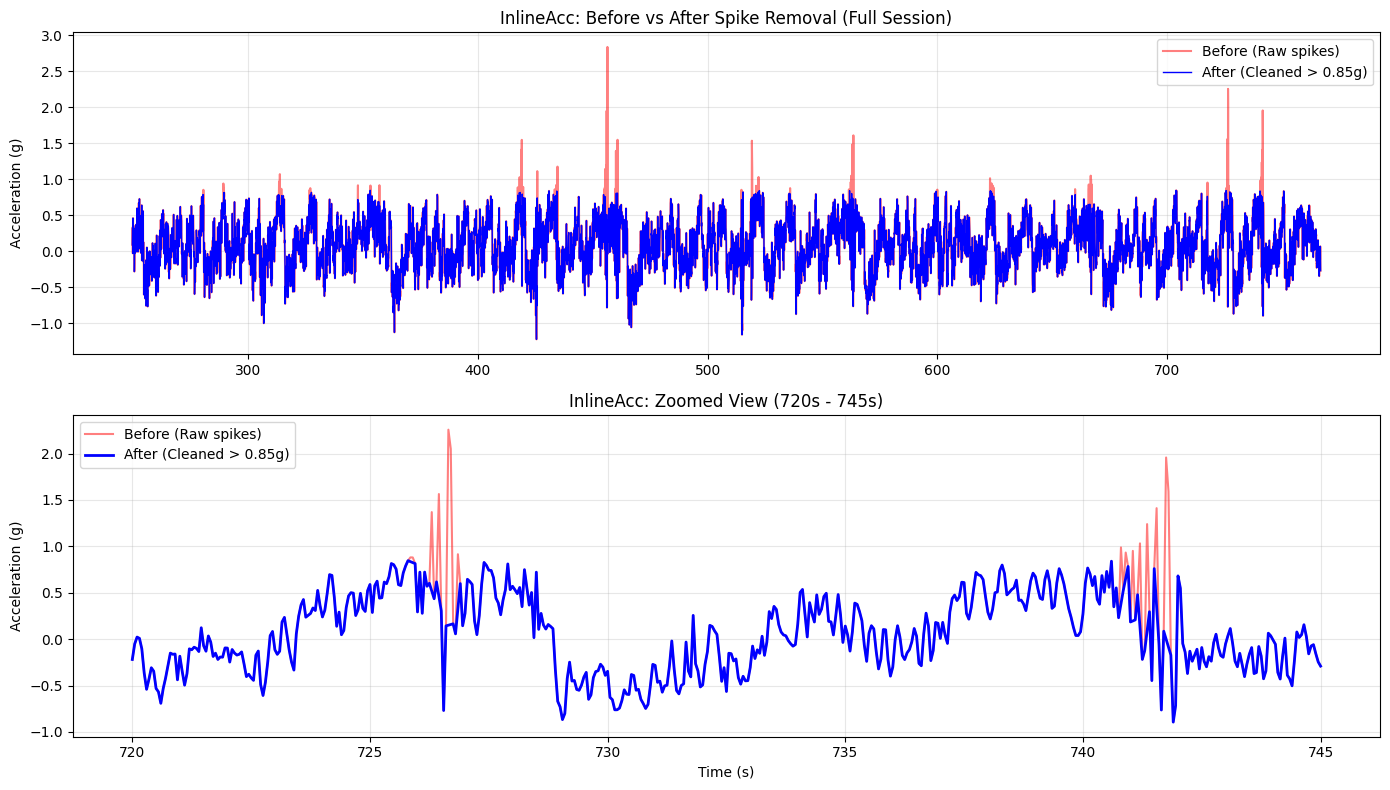

In [ ]:
# Create a 2-row figure: Full Session (top) and Zoomed Window (bottom)
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# 1. Top Plot: Full Session
axes[0].plot(df_clean.index, inline_before, label='Before (Raw spikes)', color='red', alpha=0.5)
axes[0].plot(df_clean.index, df_clean['InlineAcc'], label='After (Cleaned > 0.85g)', color='blue', linewidth=1)
axes[0].set_title('InlineAcc: Before vs After Spike Removal (Full Session)')
axes[0].set_ylabel('Acceleration (g)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Bottom Plot: Zoomed Window (720s - 745s)
mask = (df_clean.index >= 720) & (df_clean.index <= 745)
axes[1].plot(df_clean.index[mask], inline_before[mask], label='Before (Raw spikes)', color='red', alpha=0.5)
axes[1].plot(df_clean.index[mask], df_clean.loc[mask, 'InlineAcc'], label='After (Cleaned > 0.85g)', color='blue', linewidth=2)
axes[1].set_title('InlineAcc: Zoomed View (720s - 745s)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Acceleration (g)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Adjust spacing so titles/labels do not overlap
plt.tight_layout()
plt.show()

**Result:** Across the entire session (top), all vibration spikes above `0.85 g` are eliminated. In the zoomed view (bottom), we confirm that the artificial spikes (up to `+2.25 g`) were cleanly bridged while keeping the real braking and acceleration curves intact.

## 6. Final Validation & Export Clean Data
We run a final check to make sure there are zero `NaN` values left and verify the final table shape. Then, we save the cleaned telemetry data and the lap table to CSV files so we can use them directly in Chapter 3 (`03_Telemetry_Analysis.ipynb`).

In [ ]:
# Final sanity check for missing values
nan_count = df_clean.isna().sum().sum()
print(f"Total NaN values: {nan_count}")
print(f"Final cleaned shape: {df_clean.shape}")

# Save cleaned telemetry and lap boundaries
clean_file = "Lambros_testing_0356_clean.csv"
laps_file = "Lambros_testing_0356_laps.csv"

df_clean.to_csv(clean_file)
session.laps.to_csv(laps_file, index=False)

print(f"Saved {clean_file} and {laps_file} successfully!")

Total NaN values: 0
Final cleaned shape: (10350, 41)
Saved Lambros_testing_0356_clean.csv and Lambros_testing_0356_laps.csv successfully!


## Summary: Data Cleaning & Export (`02_Data_Cleaning_and_Preprocessing.ipynb`)

The raw telemetry dataset from `Lambros_testing_0356.xrk` at Serres Circuit (`10,350` samples at `20 Hz` across `5` completed laps) has been validated, cleaned, and exported for downstream analysis:

* **Dead / Constant Channels Removed:** Dropped `26` zero-variance or non-informative diagnostic channels, reducing raw channel count while preserving all `10,350` time-indexed samples.
* **RPM Standardization:** Resolved duplicate RPM signals and standardized the primary `RPM` channel so downstream lap and throttle/gear analysis relies on a single reliable source.
* **Brake Pressure Zero-Drift Calibration:** Corrected baseline zero-drift on brake pressure so unbraked states sit cleanly at zero without false braking triggers.
* **IMU Spike Removal (`InlineAcc`):** Investigated high acceleration spikes (`up to +2.840 g`) against `GPS Speed`, `TPS`, and `RPM`, confirming they resulted from mechanical/frame vibration rather than true bike acceleration (`~0.85 g` physical ceiling). Applied surgical masking (`> 0.85 g`) and linear interpolation (`InlineAcc max` reduced from `2.840 g` to `0.849 g`), while verifying `LateralAcc` remained within realistic bounds (`-0.459 g` to `0.534 g`).
* **Integrity Check & Exported Artifacts:** Confirmed `0` remaining `NaN` values across `(10,350, 41)` cleaned telemetry records and exported:
  * `Lambros_testing_0356_clean.csv` (cleaned time-series telemetry)
  * `Lambros_testing_0356_laps.csv` (lap boundaries and metadata)